# 01 · Datos crudos y transformación (Bloque 1)

Este notebook trabaja con **precios** y tiene partes con reglas distintas:

| Parte | Datos que usa | Para qué | ¿Decide el diseño? |
|---|---|---|---|
| **A. Auditoría de calidad** | Todo el rango 2010-2026 | nulos, huecos, valores ≤ 0, calendario, saltos | No: solo detecta errores de datos |
| **B. Partición** | — | verificar los cortes train / val / test definidos en `src/config.py` | — |
| **C. Diagnóstico de transformaciones** | **Solo train** | elegir log-retorno o diferencia por serie | **Sí** |
| **D. Retornos y guardado** | Toda la serie (transformación punto a punto, sin parámetros) | genera `data/processed/` | — |

Los notebooks **02** y **03** solo leen `data/processed/` y nunca abren el test.

In [1]:
import sys
from pathlib import Path

# La raíz del proyecto es la carpeta que contiene `src/` (funciona se ejecute desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

In [2]:
RAIZ

WindowsPath('c:/Users/ASUS/Desktop/Maestria IA USFQ/TESIS/DESARROLLO TESIS')

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import importlib

from src import config as cfg
import statsmodels.api as sm
from src import load_clean as lc
from src.preprocessing import construir_retornos, preparar_y_guardar, cargar
from src import eda_utils as eda

In [4]:
importlib.reload(cfg)
importlib.reload(lc)

<module 'src.load_clean' from 'c:\\Users\\ASUS\\Desktop\\Maestria IA USFQ\\TESIS\\DESARROLLO TESIS\\src\\load_clean.py'>

## 1. Revisión de la calidad de la data

In [5]:
base = lc.cargar_crudo()
print(base.shape, base.index.min().date(), "->", base.index.max().date())
base.head()

(4232, 7) 2010-01-04 -> 2026-10-20


,WTI,VIX,DXY,GOLD,TNX,SP500,NG
Date,,,,,,,
2010-01-04,81.510002,20.040001,77.529999,1117.699951,3.841,1132.989990,5.884
2010-01-05,81.769997,19.350000,77.620003,1118.099976,3.755,1136.520020,5.637
2010-01-06,83.180000,19.160000,77.489998,1135.900024,3.808,1137.140015,6.009
2010-01-07,82.660004,19.059999,77.910004,1133.099976,3.822,1141.689941,5.806
2010-01-08,82.750000,18.129999,77.470001,1138.199951,3.808,1144.979980,5.749


Se extraen  los precios al cierre de las variables consideradas dentro del proyecto, con 4232 observaciones desde el 04 de Enero del 2010 al 20 de Octubre de 2026.

Las variables a considerar son las siguientes:



| Variable | Unidades | Descripción |
|---|---|---|
| `Date` | Fecha (AAAA-MM-DD) | Fecha de observación de las variables financieras. Permite ordenar cronológicamente las series, sincronizar los datos y estudiar la evolución de los mercados financieros a lo largo del tiempo. |
| `WTI` | USD por barril (USD/bbl) | Precio internacional del petróleo West Texas Intermediate, utilizado como referencia del mercado petrolero estadounidense.  Un incremento del precio puede favorecer los ingresos petroleros, la balanza comercial y la disponibilidad de recursos fiscales, mientras que una caída puede reducirlos y aumentar las necesidades de financiamiento público. |
| `VIX` | Puntos de índice (10 a 40 puntos) | Índice de volatilidad implícita del S&P 500, que representa las expectativas del mercado sobre la volatilidad del mercado bursátil estadounidense durante los próximos 30 días, expresadas en términos anualizados. El S&P 500 agrupa aproximadamente 500 grandes empresas cotizadas en Estados Unidos. Un aumento del VIX suele reflejar mayor incertidumbre y aversión al riesgo entre los inversionistas, mientras que una disminución suele asociarse con mayor tranquilidad en los mercados. |
| `DXY` | Puntos de índice (70 a 120 puntos) | Índice del dólar estadounidense frente a una cesta de seis monedas principales. Su evolución es especialmente relevante para Ecuador debido a que el dólar es su moneda oficial. Una apreciación del dólar puede encarecer relativamente los productos ecuatorianos frente a los de países cuyas monedas se deprecian, afectando potencialmente la competitividad de las exportaciones no petroleras.  |
| `GOLD` | USD por onza troy (USD/oz t) | Precio internacional del oro expresado en dólares estadounidenses. El oro suele utilizarse como activo de inversión y reserva de valor, y puede beneficiarse de episodios de incertidumbre económica, tensiones geopolíticas o cambios en las tasas de interés reales. |
| `TNX` | Porcentaje (%) | Rendimiento del bono del Tesoro estadounidense a 10 años, indicador de las tasas de interés de largo plazo y de las condiciones financieras internacionales. Para Ecuador, al ser una economía dolarizada, es relevante porque las tasas estadounidenses influyen en el costo de referencia del financiamiento en dólares. Un incremento del TNX puede encarecer el financiamiento internacional para el sector público y privado ecuatoriano, especialmente si coincide con un aumento del riesgo país. |






In [6]:
# Nulos por columna y filas afectadas
display(lc.resumen_nulos(base))
base[base.isna().any(axis=1)]

,cantidad,porcentaje
TNX,9,0.21
GOLD,7,0.17
WTI,7,0.17
SP500,7,0.17
DXY,6,0.14
NG,6,0.14
VIX,5,0.12


,WTI,VIX,DXY,GOLD,TNX,SP500,NG
Date,,,,,,,
2010-10-11,82.209999,18.959999,77.440002,1353.300049,NaN,1165.319946,3.601
2016-01-18,NaN,NaN,99.120003,NaN,NaN,NaN,NaN
2016-10-10,NaN,13.380000,NaN,NaN,1.723,2163.659912,NaN
2016-11-11,NaN,14.170000,NaN,NaN,NaN,2164.449951,NaN
2018-01-29,65.559998,13.840000,89.309998,NaN,2.699,2853.530029,3.631
2023-11-23,NaN,NaN,NaN,1993.300049,NaN,NaN,2.934
2025-01-09,73.919998,NaN,109.180000,2690.800049,NaN,NaN,3.701
2025-05-26,NaN,NaN,98.930000,NaN,NaN,NaN,NaN
2025-07-04,66.500000,NaN,NaN,3346.500000,NaN,NaN,3.387


Para cada variable se examinan los nulos, y se encuentra para cada columna, una cantidad mínima de ellos en los años 2010,2016,2018,2023,2025 y 2026.

In [7]:
# Se eliminan las filas con algún nulo (si el % medio de nulos <= cfg.UMBRAL_NULOS)
base1, eliminadas = lc.eliminar_filas_nulas(base)
print(f"Filas eliminadas: {len(eliminadas)}  |  quedan {base1.shape[0]} filas y {base1.shape[1]} columnas")
print("Filas eliminadas por año:", eliminadas.groupby(eliminadas.index.year).size().to_dict())

Filas eliminadas: 11  |  quedan 4221 filas y 7 columnas
Filas eliminadas por año: {2010: 1, 2016: 3, 2018: 1, 2023: 1, 2025: 3, 2026: 2}


Las filas eliminadas son días en que algún mercado no operó (feriados) o hubo un dato faltante.
Se eliminan para **todas** las series, así que el retorno del día siguiente a un hueco abarca más de un día de calendario para las series que sí operaron. Con pocas filas (menos del 0,5 %) el efecto es mínimo.

In [8]:
# El índice debe ser datetime, ordenado y sin duplicados
print(base1.index.dtype, base1.index.is_monotonic_increasing, base1.index.duplicated().sum())

datetime64[us] True 0


In [9]:
# Valores <= 0, infinitos, nulos y precios repetidos por serie (todo el rango)
display(eda.chequeo_calidad(base1))

for c in base1.columns:
    malos = base1.index[base1[c] <= 0]
    if len(malos):
        print(c, [d.date() for d in malos])

print("\nValores <= 0 por tramo (train y val deben quedar limpios):")
for k, (a, b) in cfg.splits.items():
    print(k, (base1.loc[a:b] <= 0).sum().to_dict())

,min,n_<=0,n_inf,n_nulos,n_dias_sin_cambio
WTI,-37.630001,1,0,0,14
VIX,9.140000,0,0,0,19
DXY,72.930000,0,0,0,45
GOLD,1050.800049,0,0,0,17
TNX,0.499000,0,0,0,71
SP500,1022.580017,0,0,0,1
NG,1.482000,0,0,0,22


WTI [datetime.date(2020, 4, 20)]

Valores <= 0 por tramo (train y val deben quedar limpios):
train {'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'TNX': 0, 'SP500': 0, 'NG': 0}
val {'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'TNX': 0, 'SP500': 0, 'NG': 0}
test {'WTI': 1, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'TNX': 0, 'SP500': 0, 'NG': 0}


Se analizan valor negativos que pudieran afectar las transformaciones de retornos en cada fase del modelo: train, validación y test. 

> train: ("2010-01-04", "2018-12-31")

> val:   ("2019-01-01", "2019-12-31")

> test:  ("2020-01-01", "2026-10-20").

Se encontró lo siguiente:

1. Solo el WTI tiene un valor ≤ 0, el del 20/04/2020, que cae en test.
2. Train y validación están limpios, así que el diagnóstico de transformaciones y los estadísticos del EDA no se ven afectados.
3. No hay nulos ni infinitos en ninguna serie.
4. El resto de las series son positivas, así que el log-retorno es válido para todas. 
5. TNX: el mínimo de 0,499 corresponde a la tasa en porcentaje (los mínimos de 2020), así que tu escala es consistente. Lo del “×10” que mencioné antes no aplica a tus datos.

In [10]:
eda.observaciones_por_anio(base1).T

Date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n_obs,251,252,250,252,252,252,250,251,250,252,253,252,251,250,252,250,201


Para cada año se analiza la cantidad de observaciones, y no se sobservan variaciones grandes entre la cantidad de observaciones dentro de cada año.

A continuación, se analiza el cálculo de la variación logarítmica diaria y se seleccionan las 5 fechas con los mayores cambios en valor absoluto.

In [11]:
# Para cada columna, calcula la variación logarítmica diaria (día a día) 
# y selecciona las 5 fechas con los cambios más extremos en valor absoluto.

eda.saltos_extremos(base1, top=5)

,serie,fecha,|log-var|
0,WTI,2020-04-22,0.3196
1,WTI,2020-03-09,0.2822
2,WTI,2020-04-27,0.2818
3,WTI,2020-03-18,0.2799
4,WTI,2020-04-30,0.2239
5,VIX,2018-02-05,0.7682
6,VIX,2024-12-18,0.5541
7,VIX,2024-08-05,0.5002
8,VIX,2021-01-27,0.4802
9,VIX,2025-04-09,0.4424


1. Los 5 mayores saltos de la serie WTI ocurren concentrados en marzo y abril de 2020 (con variaciones logarítmicas entre 0.22 y 0.32), lo que refleja la crisis económica por la pandemia de COVID-19.
2. El VIX mide la volatilidad esperada del mercado de valores de Estados Unidos, y presenta variaciones logarítmicas extremas en cierto días, llegando hasta 0.76 (el 5 de febrero de 2018, conocido como "Volmageddon") y otras fechas como agosto de 2024. El Volmageddon es un evento  que provocó una explosión histórica y repentina en este índice debido a un efecto dominó financiero. Ese día, el miedo en el mercado se disparó y obligó a las computadoras de los grandes fondos a comprar masivamente contratos vinculados al VIX para protegerse. Como todos intentaron comprar lo mismo al mismo tiempo, causaron un colapso en cadena que destruyó por completo el valor de los productos financieros que habían apostado a que el mercado seguiría en calma.
3. En términos de magnitud numérica, las variaciones logarítmicas del DXY rondan entre 0.018 y 0.024 (aprox. 1.8% a 2.4% en un solo día). Las fechas con mayores saltos son el 24 de Junio de 2024 (El Brexit), fecha en la cual el Reino Unido salió de la Unión Europea y los picos de Noviembre 2022 por la caída de la inflación en Estados Unidos.
4.  GOLD muestra los precios futuros del oro y se observan variaciones logarítmicas entre el 0.0603 y el 0.1141, donde la más alta ocurrió el 30 de enero de 2026 con un valor de 0.1141, reflejando el histórico desplome que sufrió el metal precioso tras superar los $5,600 dólares por onza. Este ajuste extremo se debió a un fuerte shock macroeconómico generado por el endurecimiento repentino en las expectativas de tasas de interés de la Reserva Federal, lo que provocó una rápida apreciación del dólar estadounidense y desencadenó una ola masiva de liquidación de posiciones apalancadas en los mercados de futuros.
5. TNX muestra el rendimiento de los Bonos del Tesoro de EE. UU. a 10 años y se observan variaciones logarítmicas entre el 0.2672 y el 0.4048, donde la más alta ocurrió el 10 de marzo de 2020 con un valor de 0.4048. Este ajuste extremo en las tasas de interés se debió al violento shock de liquidez e incertidumbre que sacudió a los mercados globales al inicio de la pandemia de COVID-19, lo que desató una búsqueda desesperada de efectivo por parte de los inversores institucionales y obligó a intervenciones de emergencia sin precedentes por parte de la Reserva Federal.
6. SP500 representa el índice bursátil de las 500 empresas más grandes de EE. UU. y registra variaciones logarítmicas entre el 0.0888 y el 0.1277, alcanzando su pico más alto el 16 de marzo de 2020 con un valor de 0.1277. Esta drástica oscilación reflejó el pánico financiero global y las masivas ventas masivas de acciones provocadas por los confinamientos iniciales de la pandemia, marcando una de las jornadas de mayor volatilidad diaria en la historia de Wall Street y activando los mecanismos de interrupción de operaciones (circuit breakers) en las bolsas internacionales








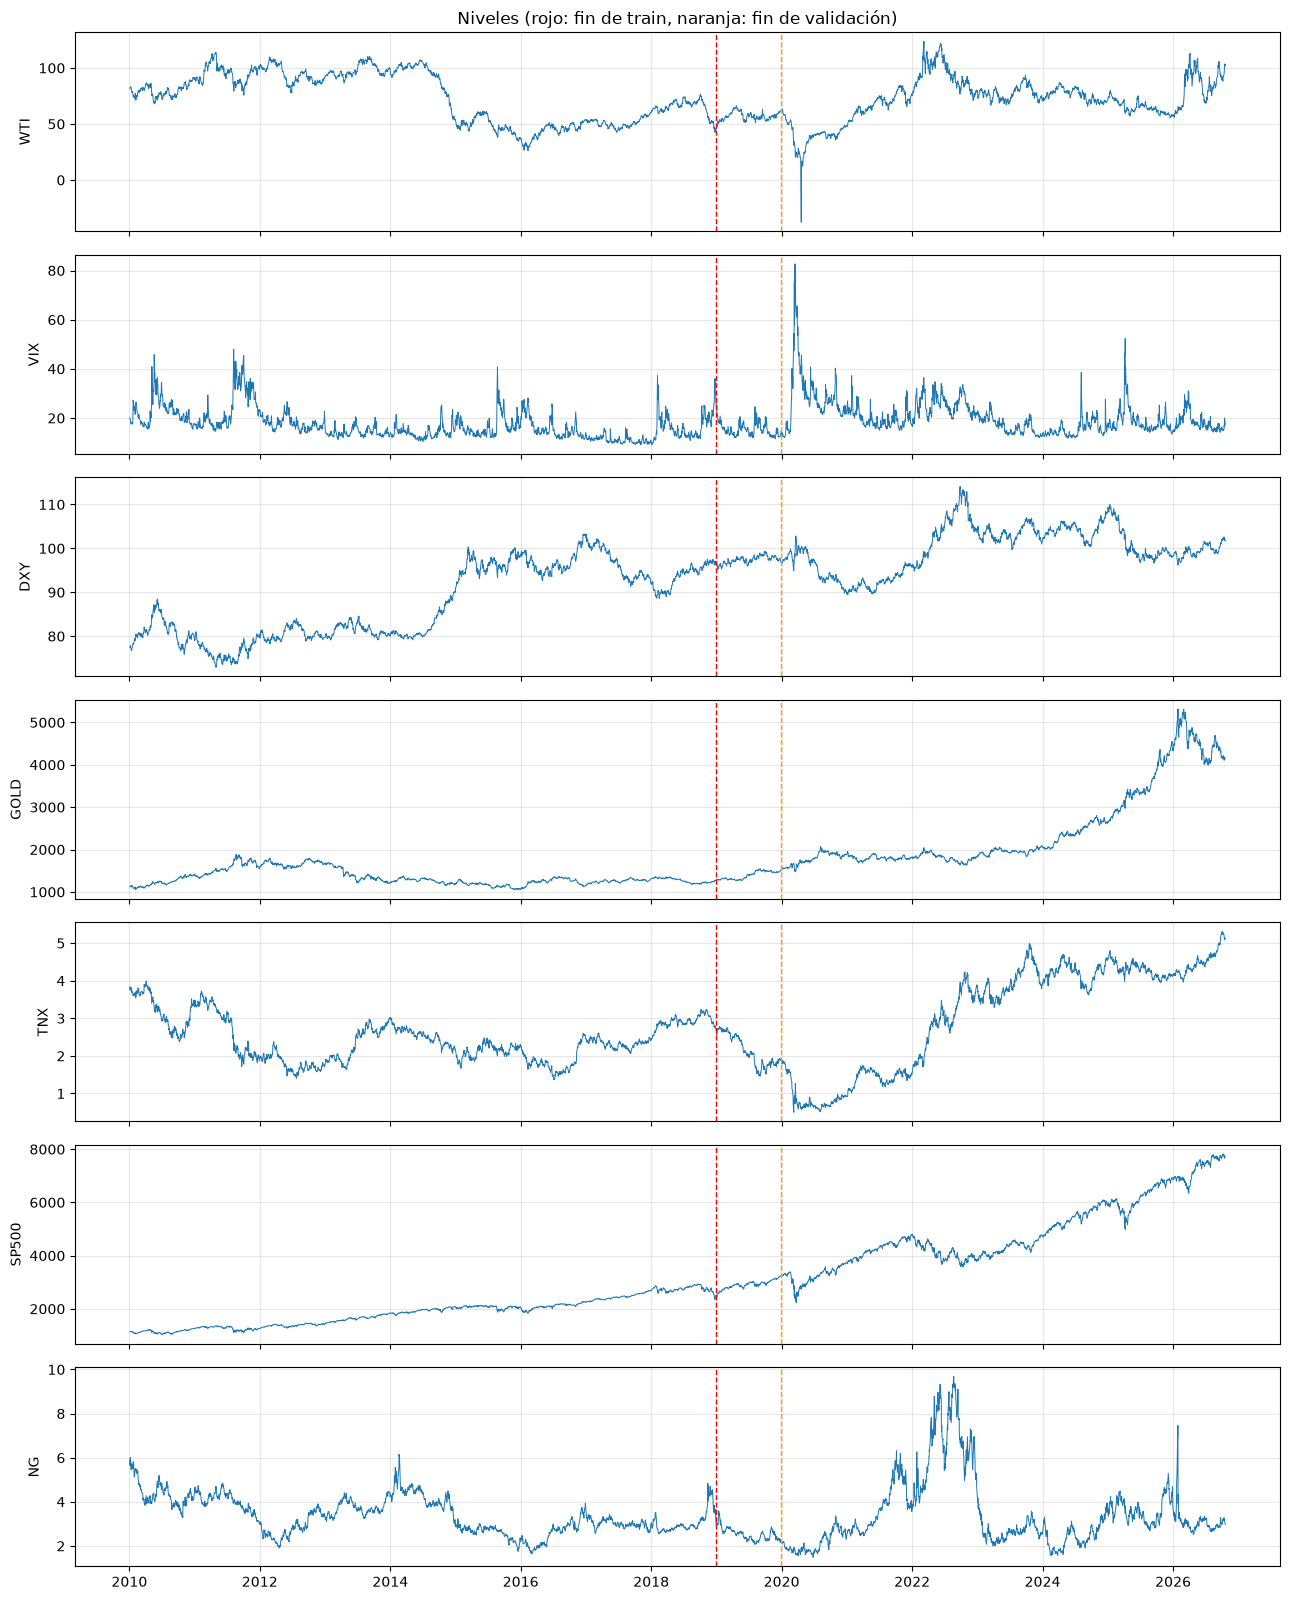

In [12]:
eda.graficar_niveles_con_cortes(base1)

A continuación definimos métricas para decidir la transformación de cada serie, para ello analizamos solamente la parte train de la serie.

In [13]:
part = lc.particionar(base1)

In [14]:
px_train = part["train"]          # precios de train: único insumo de las partes C y D
px_train.shape, px_train.index.min().date(), px_train.index.max().date()

((2260, 7), datetime.date(2010, 1, 4), datetime.date(2018, 12, 31))

In [15]:
# Descriptivos de los niveles: ¿qué escala tiene cada serie y cuándo tocó sus extremos?
eda.descriptivos_precios(px_train).round(3)

,n,media,std,CV,min,fecha_min,p25,mediana,p75,max,fecha_max,asimetria,curtosis_exceso
serie,,,,,,,,,,,,,
WTI,2260,74.234,22.414,0.302,26.210,2016-02-11,51.345,77.025,94.817,113.930,2011-04-29,-0.154,-1.378
VIX,2260,17.026,5.853,0.344,9.140,2017-11-03,13.015,15.580,19.178,48.000,2011-08-08,1.667,3.421
DXY,2260,87.283,8.217,0.094,72.930,2011-04-29,80.170,84.150,95.220,103.290,2016-12-20,0.171,-1.481
GOLD,2260,1341.757,185.570,0.138,1050.800,2015-12-17,1217.450,1285.300,1405.450,1888.700,2011-08-22,0.963,-0.095
TNX,2260,2.424,0.560,0.231,1.366,2016-07-08,1.978,2.355,2.827,3.994,2010-04-05,0.470,-0.391
SP500,2260,1856.377,520.385,0.280,1022.580,2010-07-02,1352.332,1903.820,2168.620,2930.750,2018-09-20,0.217,-1.044
NG,2260,3.388,0.806,0.238,1.639,2016-03-03,2.777,3.266,3.985,6.149,2014-02-19,0.340,-0.367


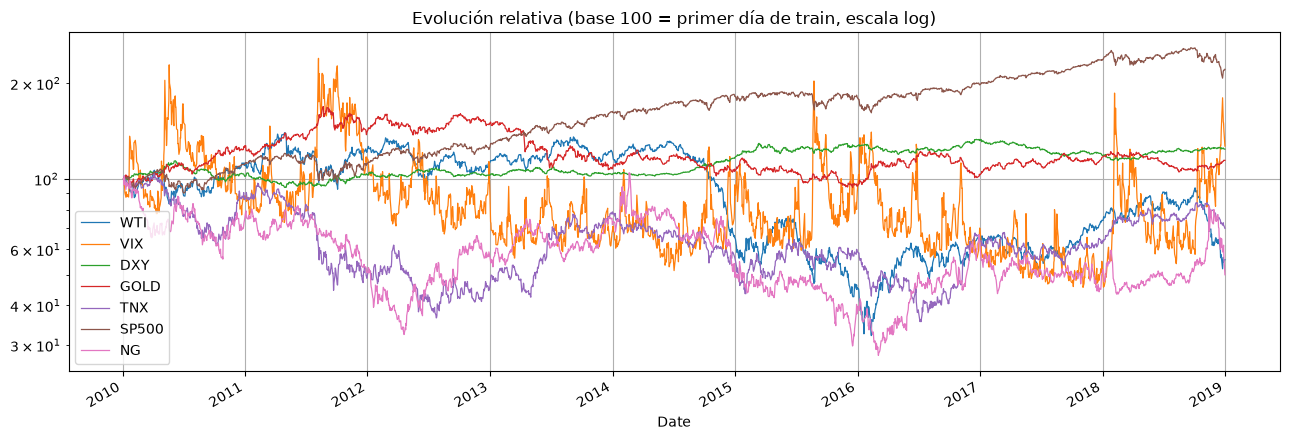

In [16]:
# Evolución relativa de todas las series en un solo gráfico
eda.graficar_base100(px_train)

La figura presenta la evolución relativa de varios indicadores financieros y materias primas (WTI, VIX, DXY, GOLD, TNX, S&P500 y NG) entre 2010 y 2019, normalizados a una base 100 al inicio del período y representados en escala logarítmica. Esta transformación permite comparar la dinámica relativa de activos con diferentes magnitudes y volatilidades.

Se observa que el S&P500 registra el mejor desempeño acumulado durante el período, pasando de una base de 100 a niveles superiores a 200, lo que refleja una tendencia alcista sostenida. El índice del dólar (DXY) y el oro (GOLD) muestran una evolución más estable, con incrementos moderados respecto al valor inicial.

En contraste, el WTI exhibe una elevada volatilidad y una marcada caída entre 2014 y 2016, período asociado al colapso de los precios internacionales del petróleo. De manera similar, el gas natural (NG) presenta fluctuaciones significativas y una tendencia general descendente respecto a su nivel inicial. El rendimiento de los bonos del Tesoro estadounidense a 10 años (TNX) también evidencia una trayectoria decreciente durante buena parte del horizonte analizado, con cierta recuperación hacia 2017-2018.

El índice de volatilidad (VIX) es la serie más errática, caracterizada por fuertes picos transitorios que reflejan episodios de incertidumbre en los mercados financieros. Estas oscilaciones son considerablemente más pronunciadas que las observadas en los demás activos.

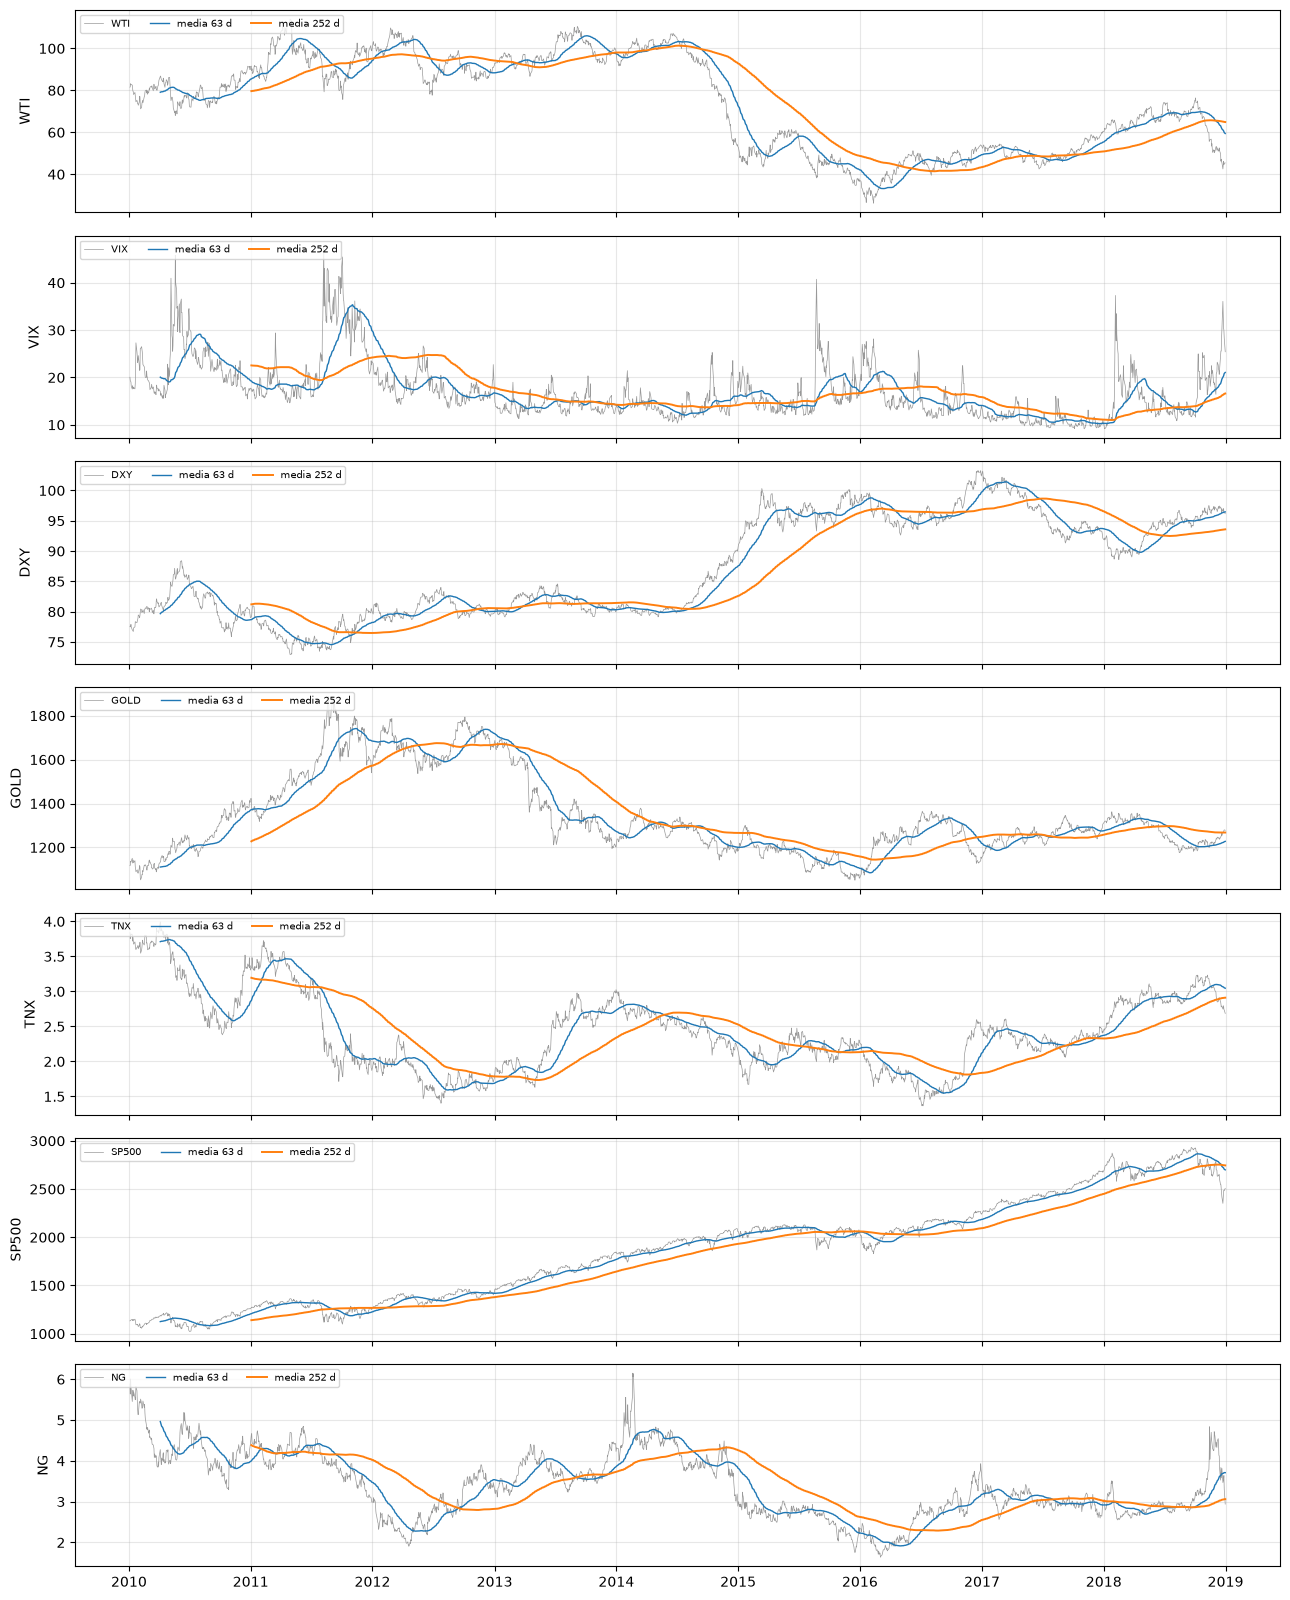

In [17]:
# Tendencias y cambios de régimen: media móvil de 63 y 252 días
eda.graficar_medias_moviles(px_train)

Las medias móviles de 63 y 252 días permiten identificar claramente los regímenes de tendencia de cada activo. El S&P500 mantiene una tendencia alcista sostenida durante casi todo el período, mientras que WTI y NG presentan cambios cíclicos marcados y episodios de alta volatilidad. El VIX muestra un comportamiento predominantemente reversivo con picos asociados a episodios de estrés financiero. Por su parte, DXY evidencia un fortalecimiento estructural desde 2014, mientras que GOLD y TNX alternan fases alcistas y bajistas sin una tendencia dominante persistente.

Desde la perspectiva de modelización, las series exhiben comportamientos heterogéneos en tendencia y volatilidad, lo que justifica trabajar con retornos o variaciones porcentuales en lugar de niveles, así como considerar posibles cambios de régimen y dependencia temporal en los análisis posteriores.

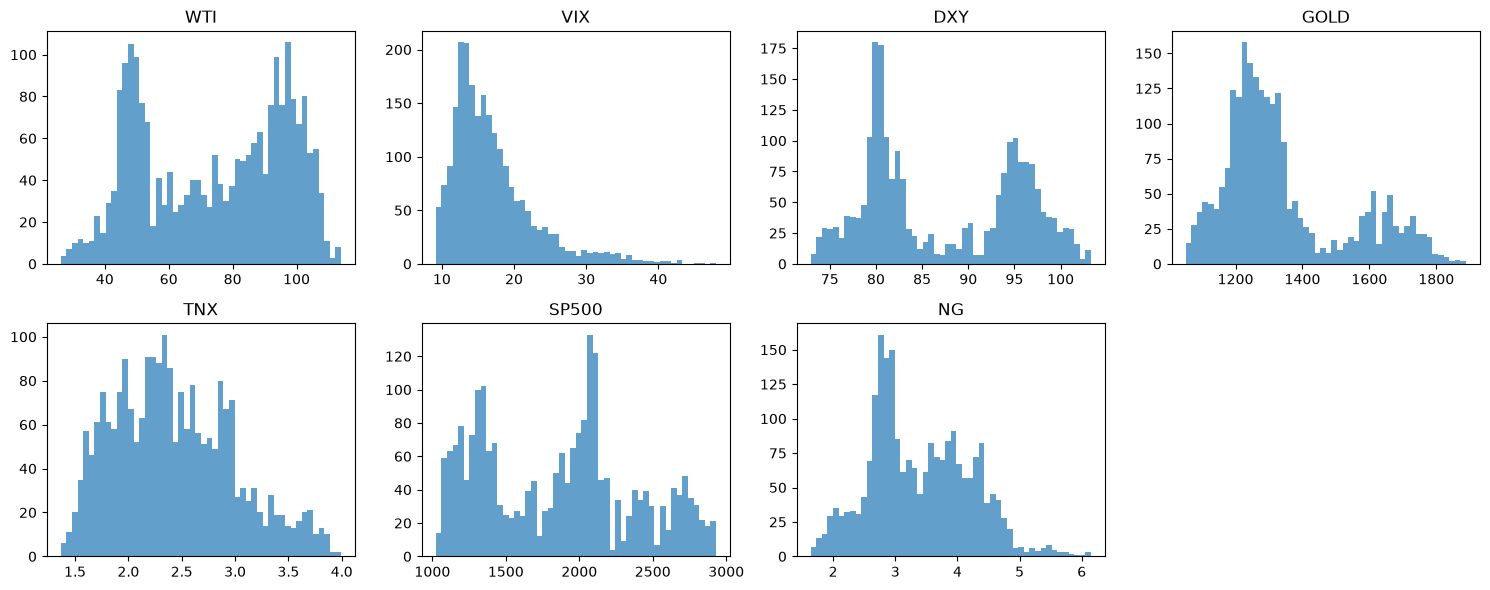

In [18]:
# Distribución de los niveles (no normal, con varias modas por los cambios de régimen)
eda.graficar_histogramas_niveles(px_train)

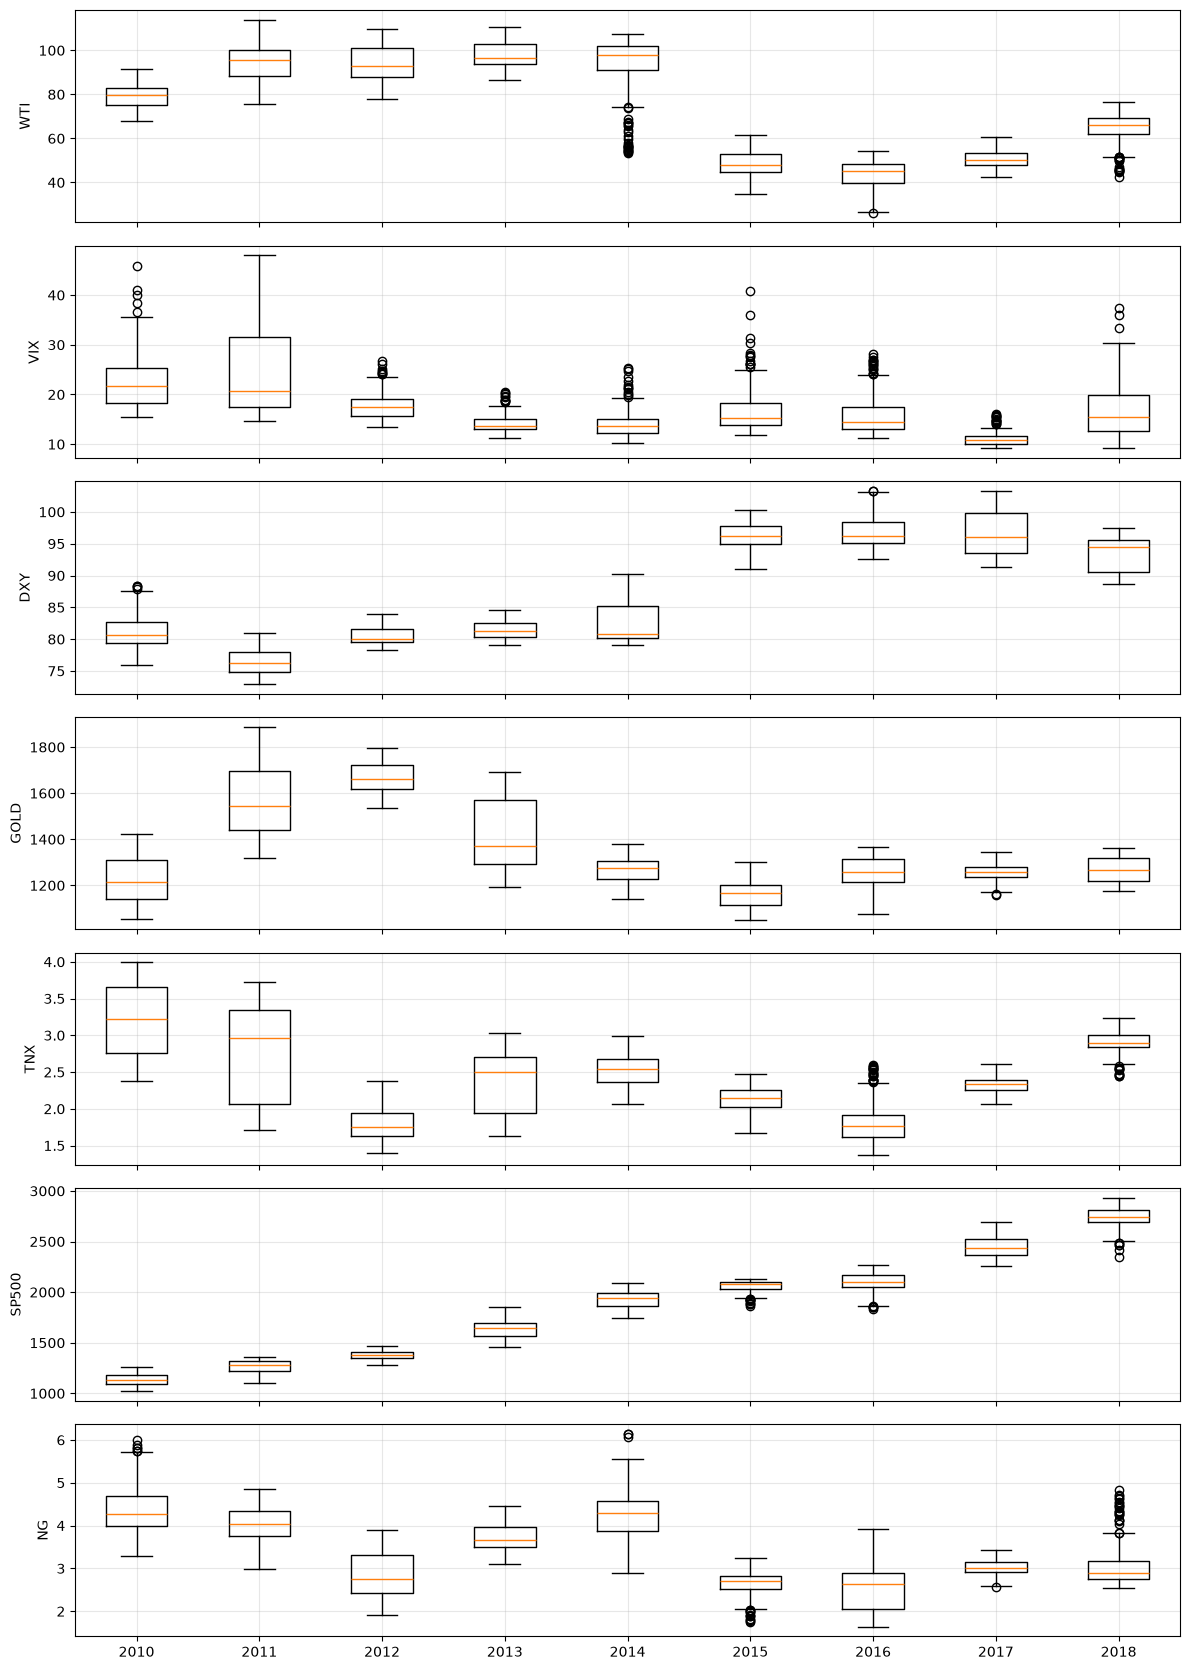

In [19]:
# Cambios de nivel y de dispersión entre años
eda.graficar_boxplot_anual(px_train)

Los diagramas de caja evidencian cambios significativos en la distribución de las variables a lo largo del tiempo. El S&P500 presenta un incremento sostenido de su mediana entre 2010 y 2018, reflejando una tendencia alcista consistente. En contraste, WTI y NG muestran una reducción importante de sus niveles centrales después de 2014, acompañada de una elevada dispersión, lo que sugiere una mayor exposición a choques de mercado.

Por su parte, el VIX exhibe la mayor cantidad de valores atípicos y una fuerte asimetría positiva, característica de una variable asociada a episodios esporádicos de alta incertidumbre financiera. El DXY muestra un desplazamiento de su distribución hacia niveles más altos a partir de 2015, mientras que GOLD y TNX alternan períodos de expansión y contracción sin mantener una tendencia uniforme durante todo el horizonte analizado.

In [20]:
# WTI por año y mayor caída (pico a valle) de cada serie dentro de train
display(eda.estadisticos_por_anio(px_train, "WTI"))
eda.tabla_drawdown(px_train)

,count,mean,std,min,median,max
Date,,,,,,
2010,251,79.60,5.20,68.01,79.68,91.51
2011,252,95.11,8.08,75.67,95.83,113.93
2012,250,94.21,7.67,77.69,92.70,109.77
2013,252,98.05,5.43,86.68,96.61,110.53
2014,252,92.91,13.37,53.27,97.74,107.26
2015,252,48.76,6.79,34.73,47.95,61.43
2016,250,43.44,6.70,26.21,45.06,54.06
2017,251,50.85,3.91,42.53,50.42,60.42
2018,250,64.95,6.70,42.53,66.29,76.41


,pico,valle,caida_%
WTI,2011-04-29,2016-02-11,-77.0
VIX,2011-08-08,2017-11-03,-81.0
DXY,2010-06-07,2011-04-29,-17.5
GOLD,2011-08-22,2015-12-17,-44.4
TNX,2010-04-05,2016-07-08,-65.8
SP500,2018-09-20,2018-12-24,-19.8
NG,2014-02-19,2016-03-03,-73.3


* **Distribución de los niveles:** no es normal ni estable; cambia entre años (boxplots), así que media y desviación globales no describen bien ninguna época.
* **Escala:** cada serie está en unidades distintas (USD, puntos de índice, % de tasa), por eso no se comparan directamente.
* **Estacionalidad:** revisa si el gas natural muestra un patrón mensual en el nivel (índice estacional distinto de 1). (falta ver estacionalidad)
* **Conclusión:** los niveles tienen tendencia y regímenes, y las correlaciones entre ellos son espurias. Hay que transformarlos, y la parte D decide cómo.

A continuación vamos a determinar el tipo de transformación que vamos a aplicar para estandarizar las variables dado que cada una se encuentra en diferentes unidades de medida. Los indicadores que se van a aplicar son los siguientes:


| Indicador | Qué mide | Límites y Criterios de Decisión |
| :--- | :--- | :--- |
| **`ADF_p`** (Augmented Dickey-Fuller - p-valor) | La estacionariedad de la serie (prueba la presencia de raíz unitaria). | **$< 0.05$**: Indica que la serie es estacionaria.<br>**$\ge 0.05$**: La serie no es estacionaria (posee raíz unitaria). |
| **`KPSS_p`** (Kwiatkowski-Phillips-Schmidt-Shin - p-valor) | La estacionariedad (prueba complementaria a ADF, con hipótesis nula invertida). | **$> 0.05$** (con tope de referencia en $0.10$): Indica que la serie es estacionaria.<br>**$\le 0.05$**: La serie no es estacionaria. |
| **`asimetria`** | El sesgo o grado de asimetría en la distribución de los datos. | **$> 0$**: Asimetría positiva (cola derecha más larga, sesgo hacia valores altos).<br>**$= 0$**: Distribución simétrica.<br>**$< 0$**: Asimetría negativa (cola izquierda más larga, sesgo hacia valores bajos). |
| **`curtosis`** (en exceso) | El peso de las colas y la concentración alrededor de la media respecto a una distribución normal. | **$> 0$**: Leptocúrtica (colas más pesadas que la normal, mayor propensión a *outliers* o valores extremos).<br>**$= 0$**: Mesocúrtica (distribución normal).<br>**$< 0$**: Platicúrtica (colas más ligeras que la normal, valores más uniformemente distribuidos). |
| **`corr_abs_nivel`** | La correlación lineal entre la magnitud absoluta de la variación y el nivel de la serie. | **$\approx 0$ (entre $-0.1$ y $0.1$)**: Escala adecuada (volatilidad independiente del precio).<br>**$> 0.1$**: Movimientos mayores cuando el precio es alto.<br>**$< -0.1$**: Movimientos mayores cuando el precio es bajo. |
| **`spearman_abs_nivel`** | La relación monotónica entre el cambio absoluto y el nivel (versión robusta a *outliers*). | **$\approx 0$ (entre $-0.1$ y $0.1$)**: Escala adecuada sin distorsión por valores extremos.<br>**$> 0.1$**: Relación de escala creciente (mayor volatilidad a mayor precio, resistente a *outliers*).<br>**$< -0.1$**: Relación de escala decreciente (mayor volatilidad a menor precio, resistente a *outliers*). |
| **`ratio_std_alto_bajo`** | La estabilidad de la dispersión comparando la desviación estándar del tercil más alto del nivel frente al tercil más bajo. | **$\approx 1$**: Escala estable entre niveles de precio.<br>**$> 1$**: La variabilidad es mayor en la zona de precios altos (sugiere aplicar logaritmo).<br>**$< 1$**: La variabilidad es mayor en la zona de precios bajos. |

In [21]:
diag = eda.diagnostico_transformaciones(px_train)
print(diag.to_string(index=False))

serie transf    n  ADF_p  KPSS_p  asimetria  curtosis  corr_abs_nivel  ADF_stat  spearman_abs_nivel  ratio_std_alto_bajo
  WTI  nivel 2260 0.7174    0.01    -0.1540   -1.3778          1.0000   -1.0941              1.0000                  NaN
  WTI   diff 2259 0.0000    0.10    -0.2654    2.9116          0.0651  -49.6979              0.0386               1.1704
  WTI logret 2259 0.0000    0.10     0.0038    2.9703         -0.3016  -33.5338             -0.2748               0.5335
  VIX  nivel 2260 0.0034    0.01     1.6672    3.4210          1.0000   -3.7577              1.0000                  NaN
  VIX   diff 2259 0.0000    0.10     1.7234   21.6653          0.5266  -13.2451              0.4422               3.9182
  VIX logret 2259 0.0000    0.10     1.1126    7.2181          0.2746  -15.4314              0.2281               1.8915
  DXY  nivel 2260 0.6638    0.01     0.1711   -1.4808          1.0000   -1.2226              1.0000                  NaN
  DXY   diff 2259 0.0000    0.10

A partir de los resultados de las pruebas de estacionariedad ADF y KPSS, los coeficientes de asimetría y curtosis, la correlación entre las variaciones absolutas y los niveles, y la relación de desviaciones estándar entre regímenes de valores altos y bajos, se evaluó la conveniencia de aplicar diferencias absolutas o rendimientos logarítmicos a las siete series analizadas.

Los resultados sugieren utilizar rendimientos logarítmicos para DXY, GOLD, SP500 y NG, debido a sus propiedades de estacionariedad, mayor estabilidad relativa de dispersión y mejoras en las características distributivas respecto a las diferencias absolutas.

Para TNX, se recomienda aplicar diferencias absolutas, tanto por la interpretación económica de las variaciones de los rendimientos de los bonos del Tesoro como por los resultados de estabilidad y curtosis.

En el caso del WTI, los rendimientos logarítmicos resultan apropiados cuando el objetivo es analizar variaciones relativas del precio; sin embargo, las diferencias absolutas presentan mejores indicadores de estabilidad de dispersión, por lo que la elección deberá considerar el propósito del modelo y verificar la positividad de los precios.

Para el VIX, los rendimientos logarítmicos mejoran los indicadores de asimetría, curtosis y dispersión respecto a las diferencias absolutas. No obstante, dada la naturaleza del índice como medida de volatilidad y los resultados contradictorios de estacionariedad en niveles, se recomienda evaluar adicionalmente la transformación logarítmica del nivel, especialmente en modelos que busquen capturar persistencia o reversión a la media.

Finalmente, debido a las distintas unidades de medida de las series, se recomienda considerar una estandarización posterior cuando las características del modelo lo requieran. La elección definitiva deberá complementarse con diagnósticos de autocorrelación, heterocedasticidad, estabilidad temporal y desempeño del modelo estimado.

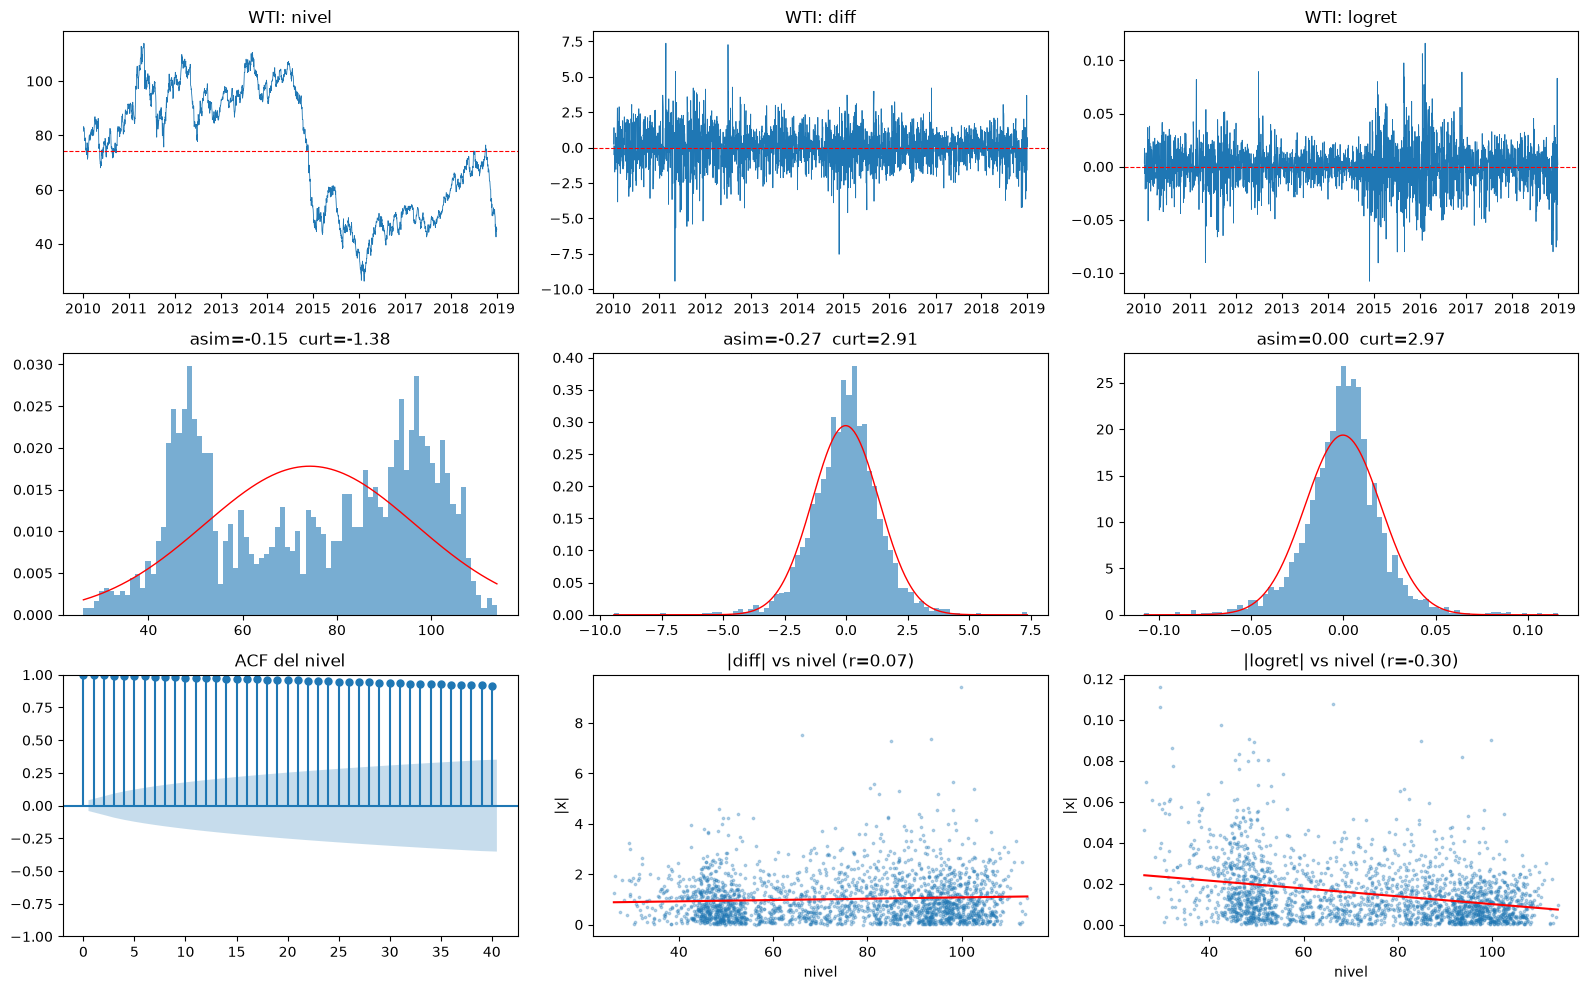

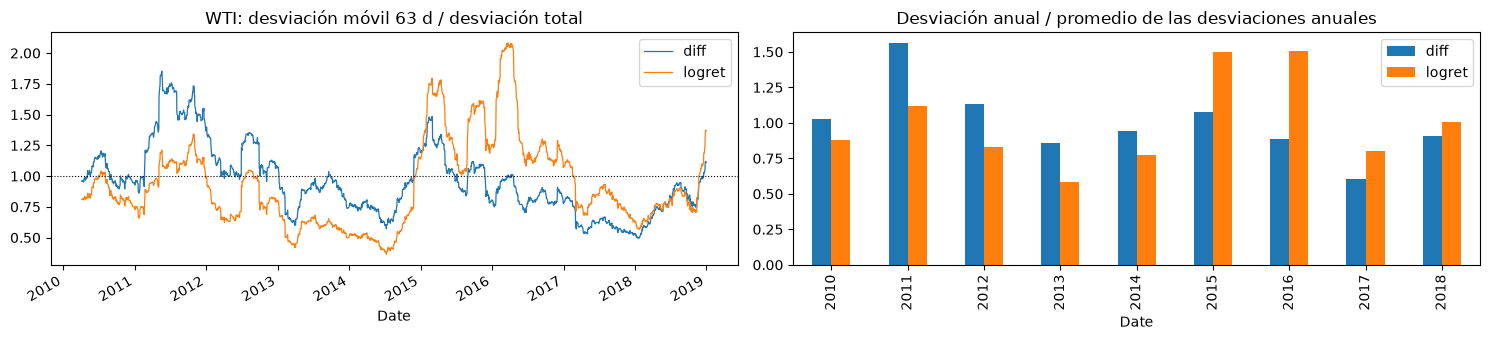

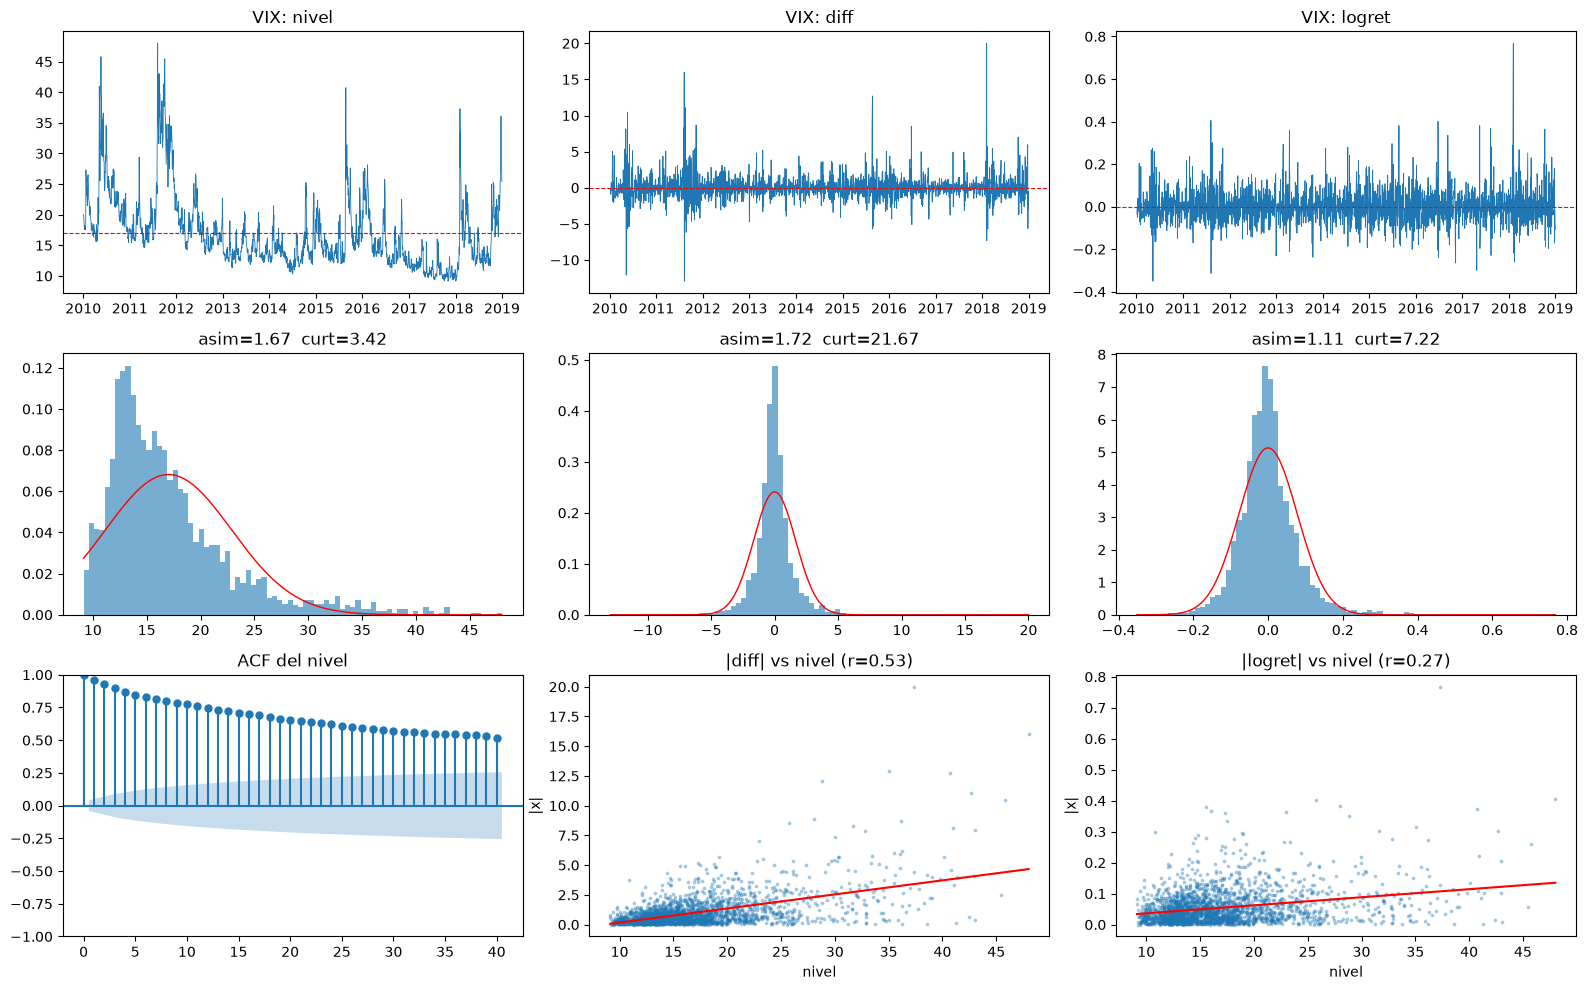

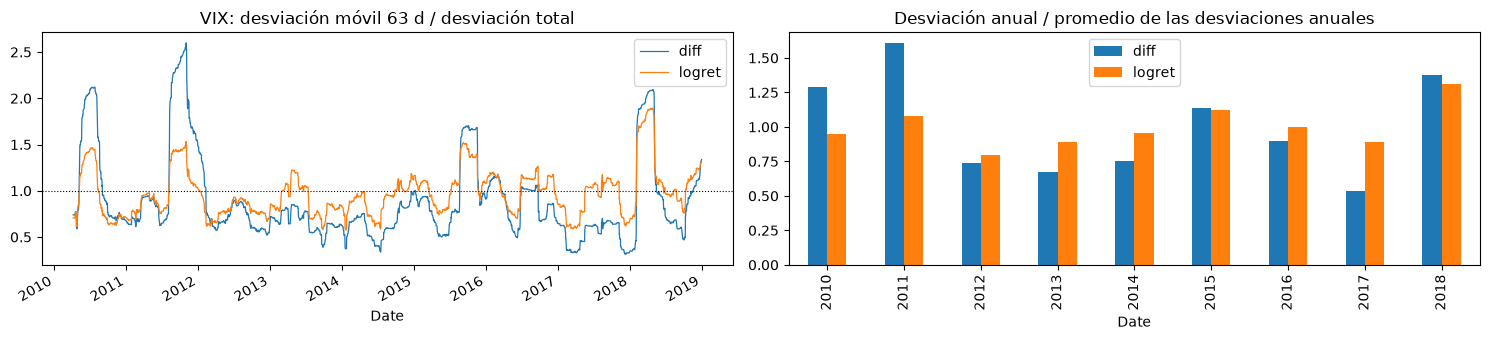

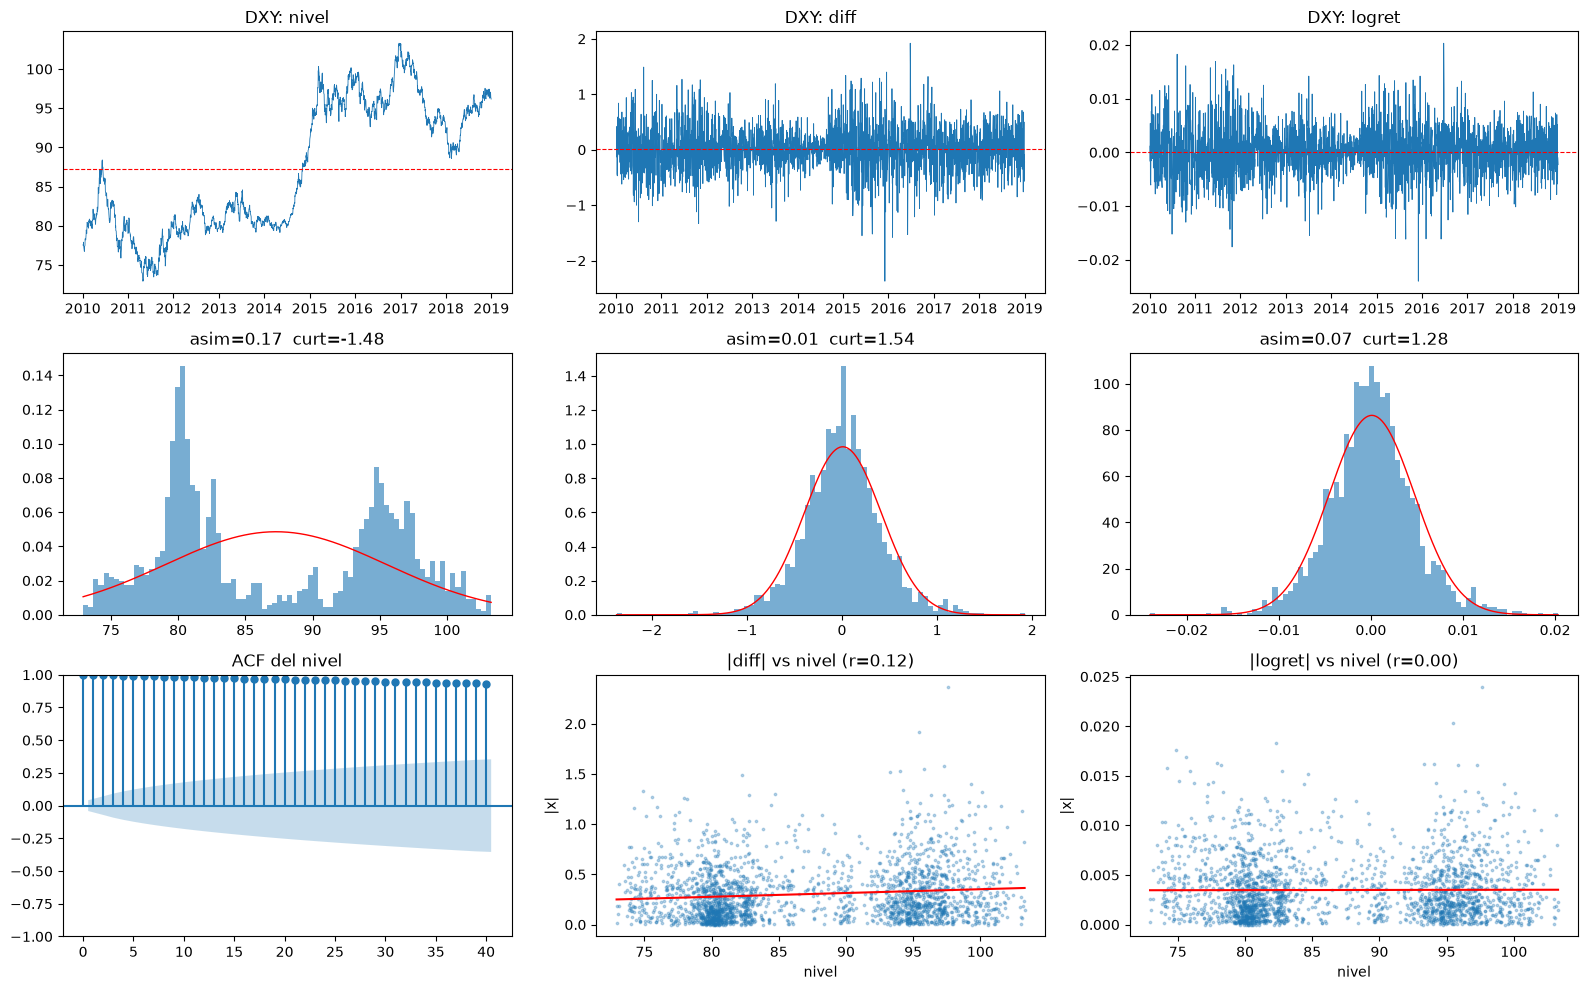

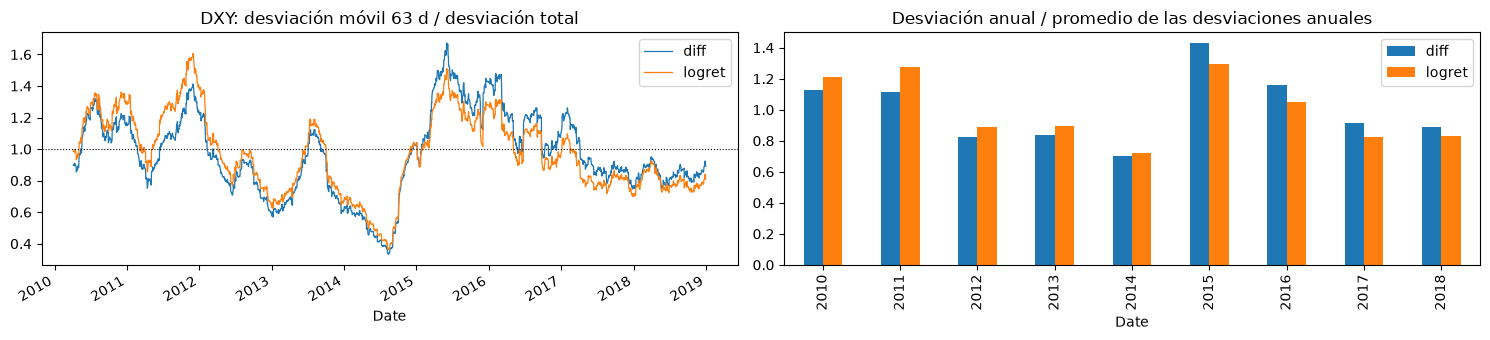

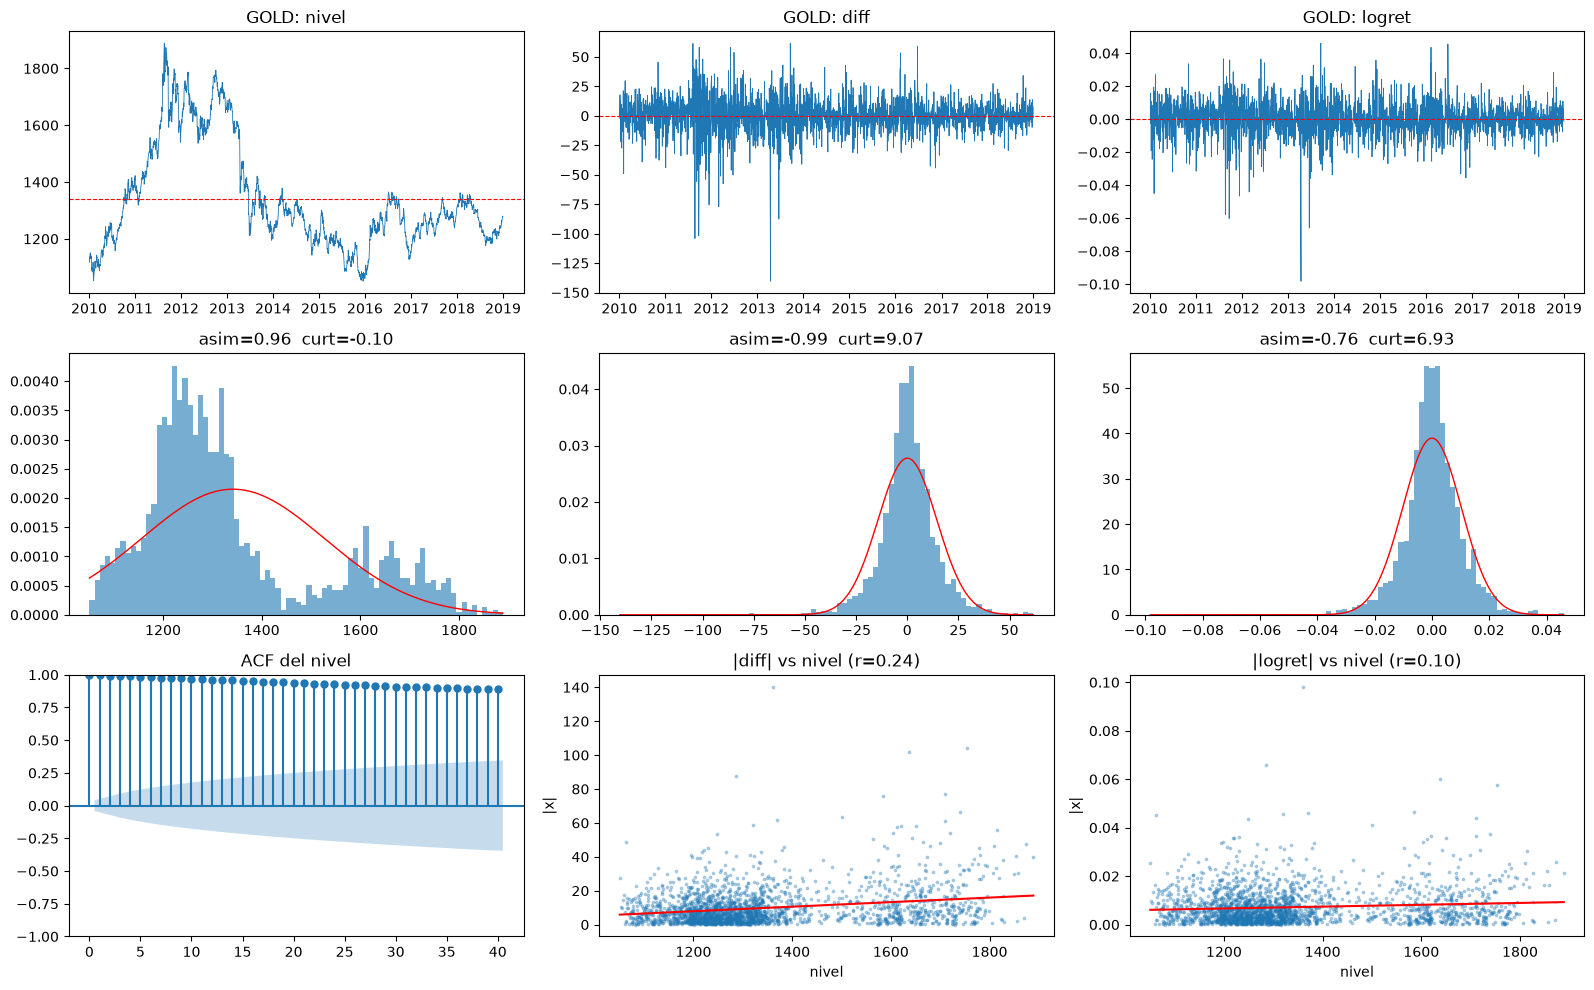

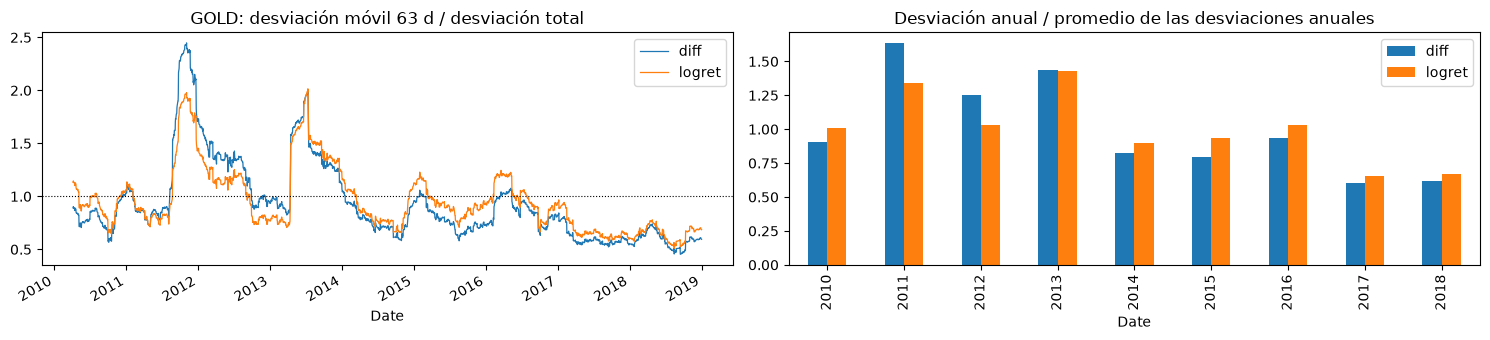

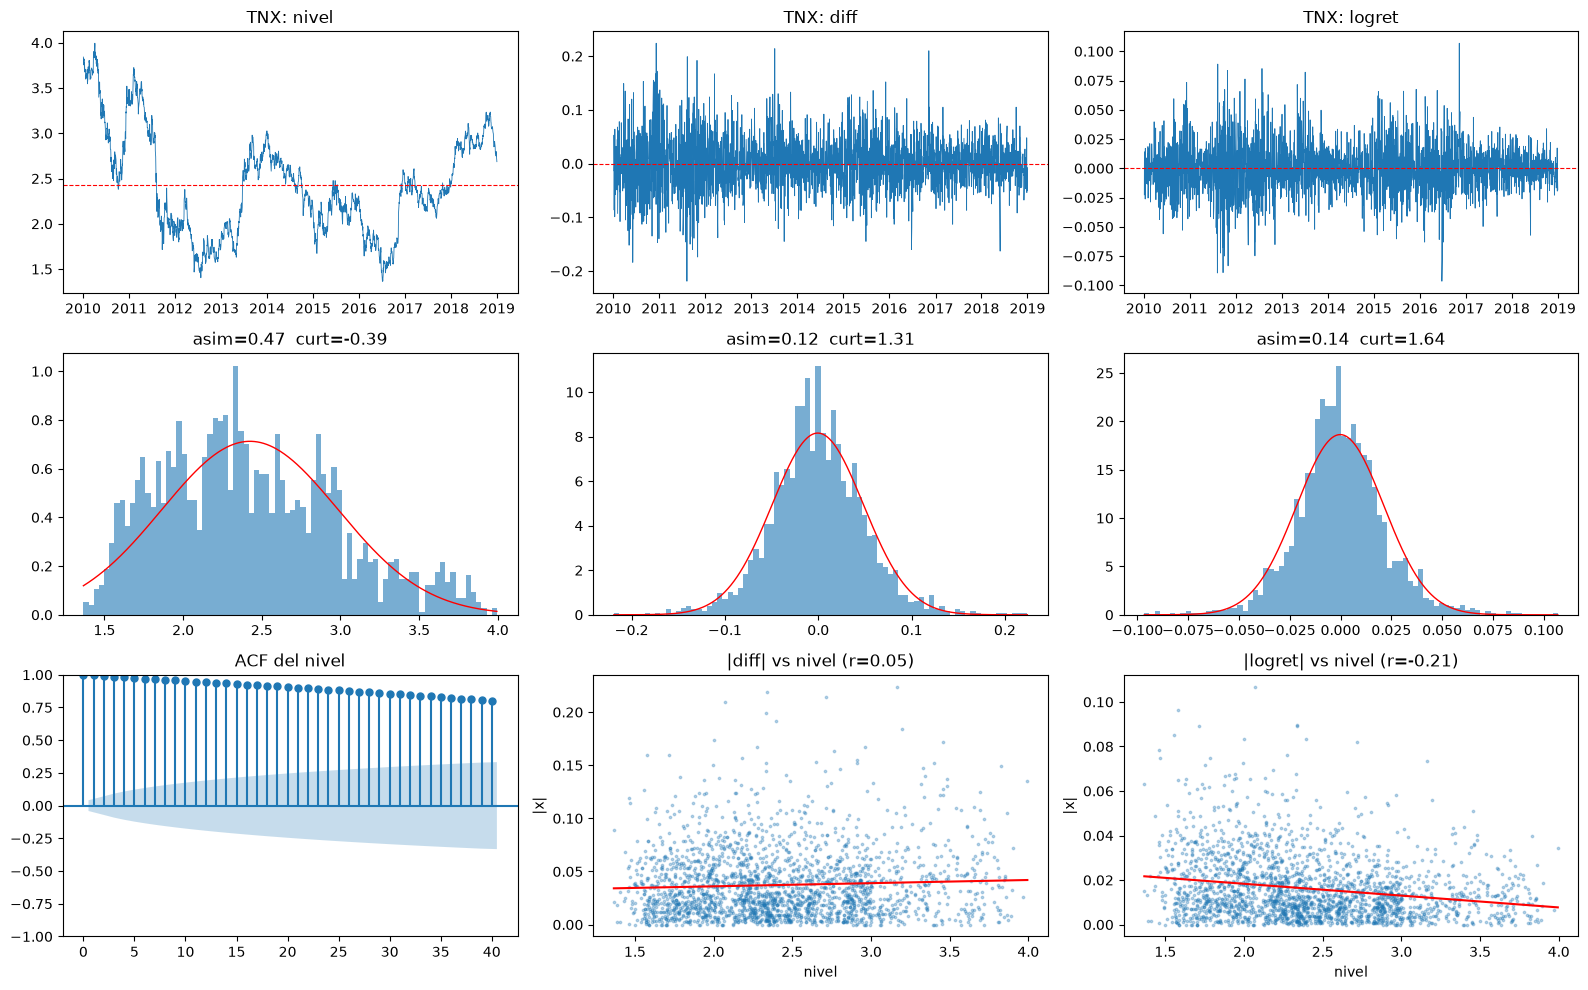

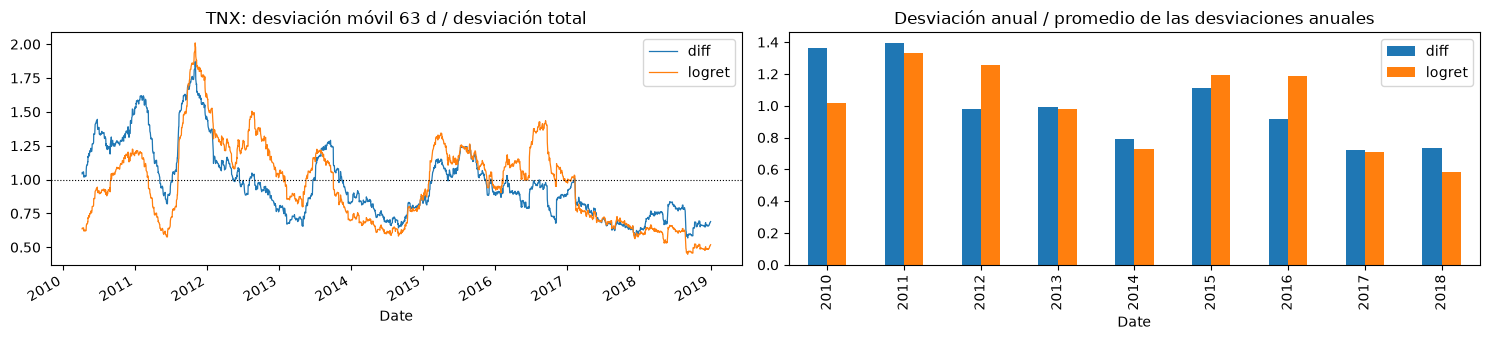

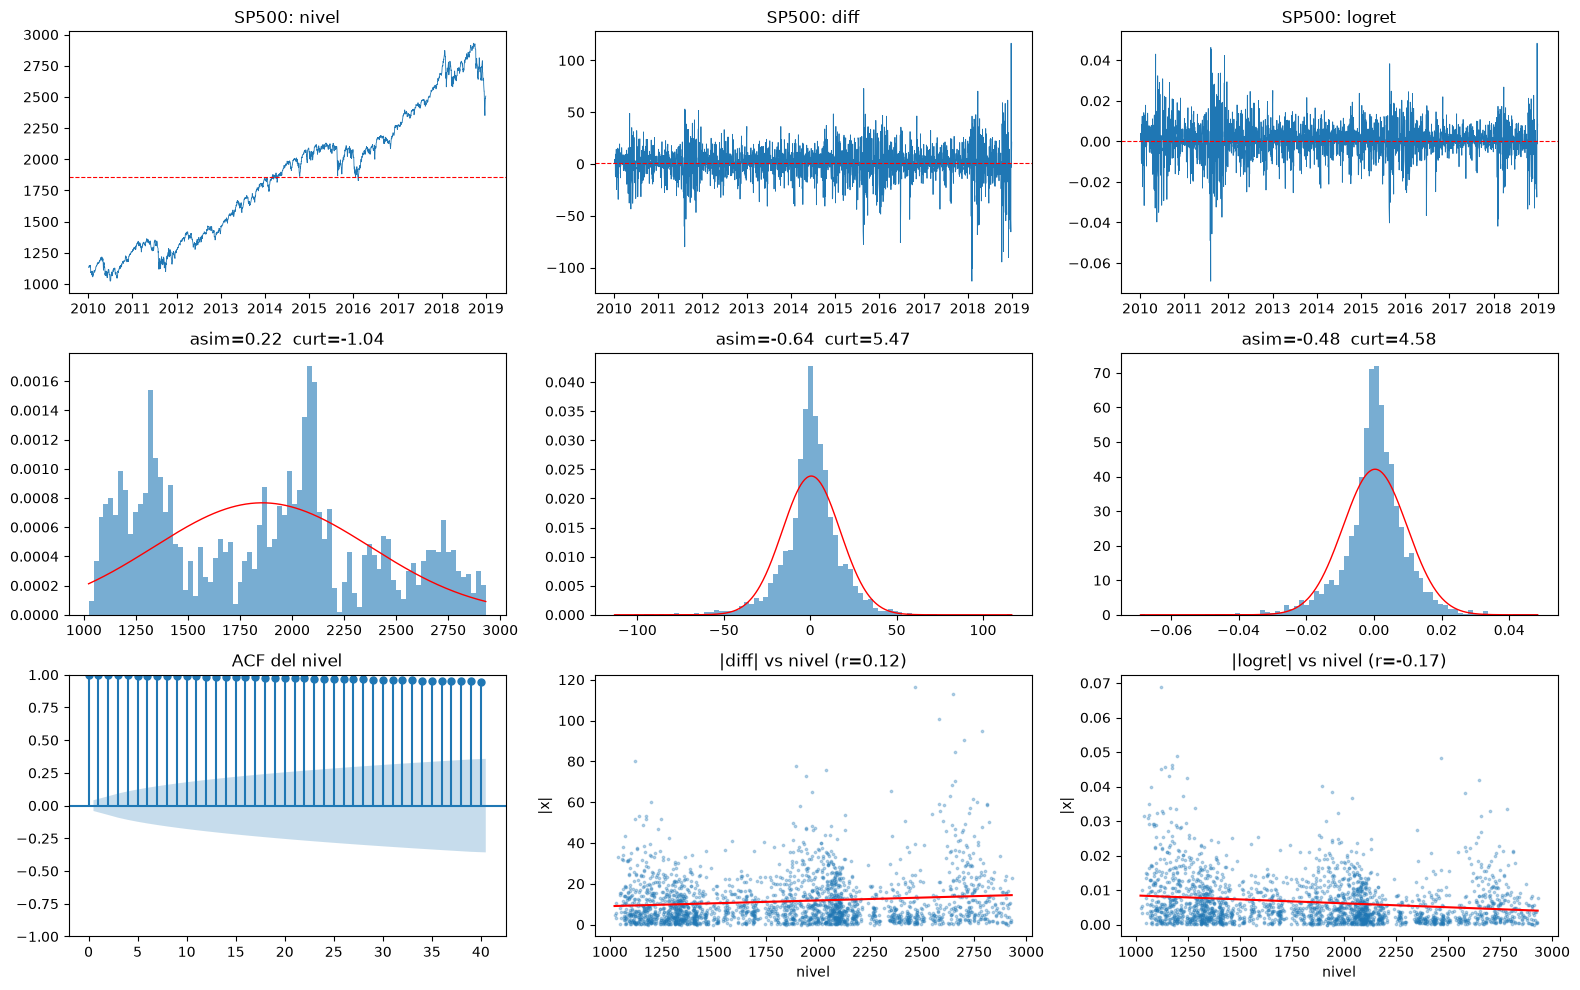

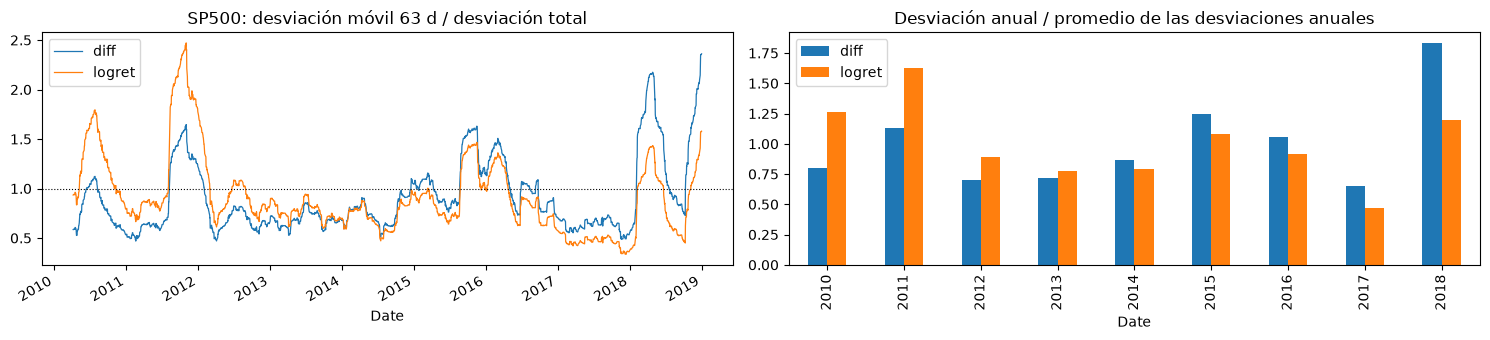

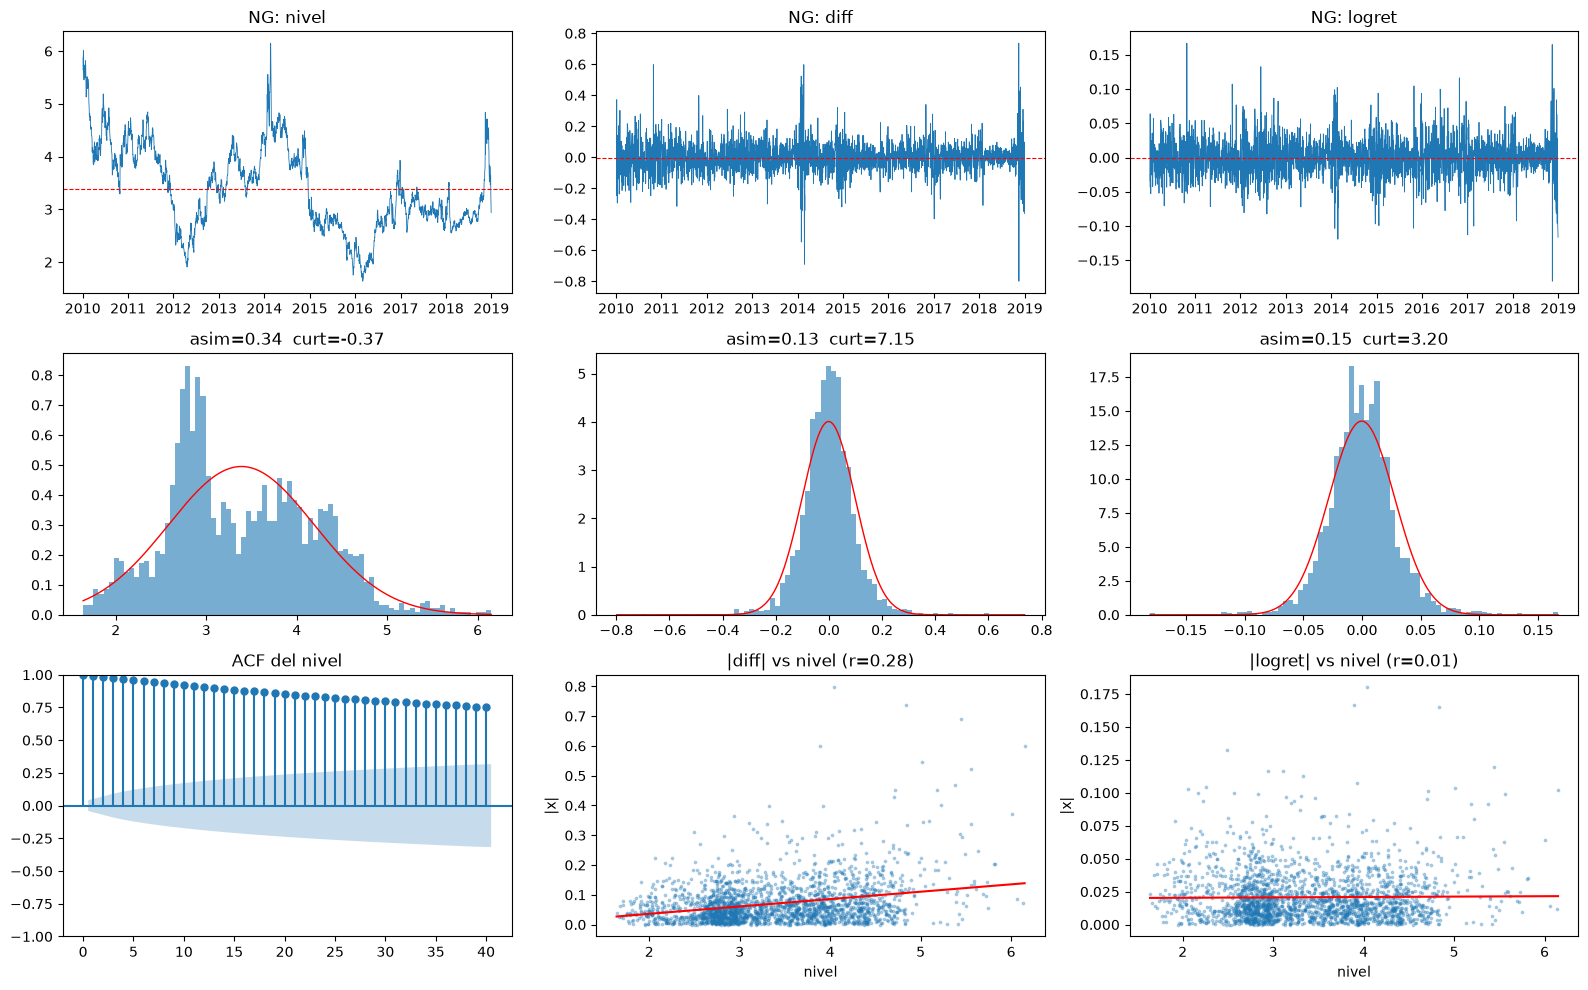

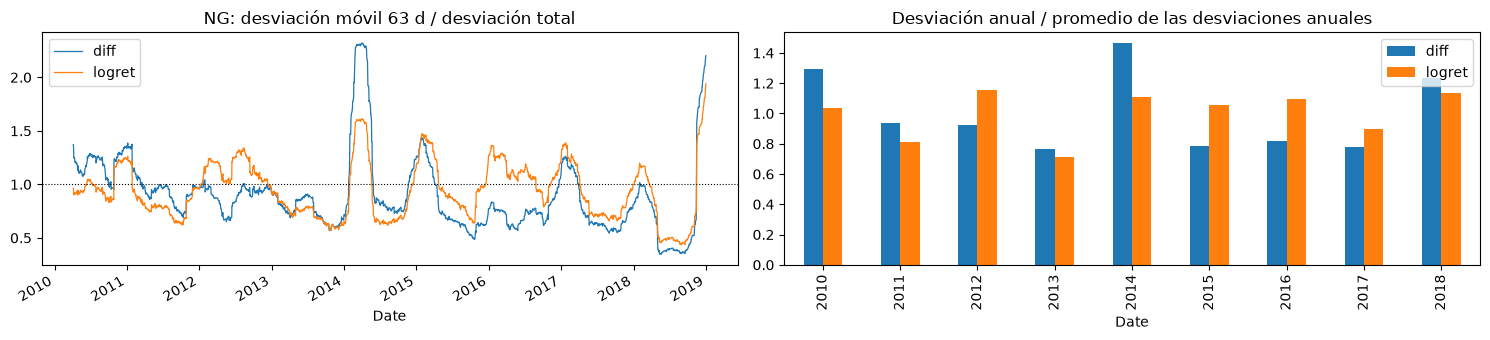

In [22]:
for c in px_train.columns:
    eda.graficar_transformaciones(px_train, c)
    eda.graficar_vol(px_train, c)

In [23]:
eda.elasticidad_vol_nivel(px_train, ["WTI", "SP500"])

,serie,ventana,k,IC95_inf,IC95_sup
0,WTI,21,0.247,0.073,0.420
1,WTI,63,0.288,0.031,0.544
2,WTI,126,0.327,-0.004,0.659
3,SP500,21,0.341,0.037,0.644
4,SP500,63,0.344,-0.056,0.743
5,SP500,126,0.367,-0.092,0.827


In [24]:
# La decisión vive en src/config.py (TRANSF). Si cambia el diagnóstico, se edita allí.
pd.Series(cfg.transf, name="transformación")

WTI      logret
VIX      logret
DXY      logret
GOLD     logret
SP500    logret
NG       logret
TNX        diff
Name: transformación, dtype: str

In [25]:
# Transformación punto a punto sobre toda la serie (no aprende parámetros, no hay fuga)
ret = construir_retornos(base1)
ret_part = lc.particionar(ret)

for k, v in ret_part.items():
    print(f"{k:6s} {v.index.min().date()} -> {v.index.max().date()}  n={len(v)}  nulos={v.isna().sum().to_dict()}")

print("infinitos:", np.isinf(ret).sum().sum())
print("fechas con NaN en WTI:", [d.date() for d in ret.index[ret['WTI'].isna()]])

assert ret_part["train"].isna().sum().sum() == 0
assert ret_part["val"].isna().sum().sum() == 0
assert ret_part["test"].isna().sum().sum() == 2        # solo WTI: 20/04 y 21/04/2020
lc.verificar_particion(ret, ret_part)

# Retorno acumulado a través del hueco del 20-21/04/2020 (evaluación complementaria)
acum = np.log(base1.loc["2020-04-21", "WTI"]) - np.log(base1.loc["2020-04-17", "WTI"])
print(f"log-retorno acumulado WTI 17/04 -> 21/04/2020: {acum:.4f}")

train  2010-01-05 -> 2018-12-31  n=2259  nulos={'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'SP500': 0, 'NG': 0, 'TNX': 0}
val    2019-01-02 -> 2019-12-31  n=252  nulos={'WTI': 0, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'SP500': 0, 'NG': 0, 'TNX': 0}
test   2020-01-02 -> 2026-10-20  n=1709  nulos={'WTI': 2, 'VIX': 0, 'DXY': 0, 'GOLD': 0, 'SP500': 0, 'NG': 0, 'TNX': 0}
infinitos: 0
fechas con NaN en WTI: [datetime.date(2020, 4, 20), datetime.date(2020, 4, 21)]
log-retorno acumulado WTI 17/04 -> 21/04/2020: -0.6017


In [26]:
# Verificación de estacionariedad de las series transformadas (train)
from statsmodels.tsa.stattools import adfuller, kpss

filas = []
for c in ret_part["train"].columns:
    s = ret_part["train"][c].dropna()
    filas.append({"serie": c, "ADF_p": adfuller(s, autolag="AIC")[1],
                  "KPSS_p": kpss(s, regression="c", nlags="auto")[1]})
pd.DataFrame(filas).set_index("serie").round(4)

,ADF_p,KPSS_p
serie,,
WTI,0.0,0.1
VIX,0.0,0.1
DXY,0.0,0.1
GOLD,0.0,0.1
SP500,0.0,0.1
NG,0.0,0.1
TNX,0.0,0.1


### Guardado de los datos procesados

`preparar_y_guardar()` ejecuta crudo → limpieza → retornos → partición y escribe `data/processed/`.
También se puede correr desde la terminal: `python -m src.preprocessing`.

In [27]:
preparar_y_guardar()
sorted(p.name for p in cfg.procesados.iterdir())

['filas_eliminadas_por_nulos.csv',
 'precios_test.csv',
 'precios_train.csv',
 'precios_val.csv',
 'retornos_test.csv',
 'retornos_train.csv',
 'retornos_val.csv']

In [28]:
preparar_y_guardar()
sorted(p.name for p in cfg.procesados.iterdir())

['filas_eliminadas_por_nulos.csv',
 'precios_test.csv',
 'precios_train.csv',
 'precios_val.csv',
 'retornos_test.csv',
 'retornos_train.csv',
 'retornos_val.csv']

A partir de aquí el test queda cerrado: `cargar("retornos", "test")` lanza un error salvo que se pida con `permitir_test=True`
(solo en el notebook de evaluación final).

In [29]:
try:
    cargar("retornos", "test")
except PermissionError as e:
    print("OK, bloqueado:", e)

OK, bloqueado: El test está reservado para la evaluación final. Usa permitir_test=True solo en el notebook de evaluación.
